In [101]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import os
from pathlib import Path

PROJECT_ROOT = Path.cwd()
while PROJECT_ROOT != PROJECT_ROOT.parent and not (PROJECT_ROOT / "data" / "Intel_Image_Classification" / "data_classifier").is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent
DATASET_DIR = PROJECT_ROOT / "data" / "Intel_Image_Classification" / "data_classifier"
if not DATASET_DIR.is_dir():
    raise FileNotFoundError(f"Dataset directory not found: {DATASET_DIR}")
datasetPath = str(DATASET_DIR)
MODELS_DIR = PROJECT_ROOT / "models"
MODELS_DIR.mkdir(parents=True, exist_ok=True)
BEST_MODEL_PATH = MODELS_DIR / "scene_classifier_best.keras"
CLASS_NAMES_PATH = MODELS_DIR / "scene_classes.json"

def explorationPreparation():
    
    totalImage = 0
    data = []
    for classe in os.listdir(datasetPath):
            chemin = os.path.join(datasetPath, classe)
            if os.path.isdir(chemin):
                images = os.listdir(chemin)
                totalImage += len(images)
    
    for classe in os.listdir(datasetPath):
        chemin = os.path.join(datasetPath, classe)
        if os.path.isdir(chemin):
            images = os.listdir(chemin)
            prc = (len(images) / totalImage) * 100
            data.append({"classe": classe,
                        "porcentage": prc,
                        "totalImage": len(images)})
    return data
explorationPreparation()


def getImagesClasse():
    data = []

    for classe in os.listdir(datasetPath):
        chemin = os.path.join(datasetPath, classe)

        if os.path.isdir(chemin):
            images = []

            for image in os.listdir(chemin):
                chemin_image = os.path.join(chemin, image)

                if os.path.isfile(chemin_image):
                    images.append(chemin_image)

            data.append({
                "classe": classe,
                "images": images
            })

    return data
print(getImagesClasse())

[{'classe': 'buildings', 'images': ['c:\\Users\\ycode\\Documents\\workespace\\VisionClassifier\\data\\Intel_Image_Classification\\data_classifier\\buildings\\0.jpg', 'c:\\Users\\ycode\\Documents\\workespace\\VisionClassifier\\data\\Intel_Image_Classification\\data_classifier\\buildings\\10006.jpg', 'c:\\Users\\ycode\\Documents\\workespace\\VisionClassifier\\data\\Intel_Image_Classification\\data_classifier\\buildings\\1001.jpg', 'c:\\Users\\ycode\\Documents\\workespace\\VisionClassifier\\data\\Intel_Image_Classification\\data_classifier\\buildings\\10014.jpg', 'c:\\Users\\ycode\\Documents\\workespace\\VisionClassifier\\data\\Intel_Image_Classification\\data_classifier\\buildings\\10018.jpg', 'c:\\Users\\ycode\\Documents\\workespace\\VisionClassifier\\data\\Intel_Image_Classification\\data_classifier\\buildings\\10029.jpg', 'c:\\Users\\ycode\\Documents\\workespace\\VisionClassifier\\data\\Intel_Image_Classification\\data_classifier\\buildings\\10032.jpg', 'c:\\Users\\ycode\\Documents\\w

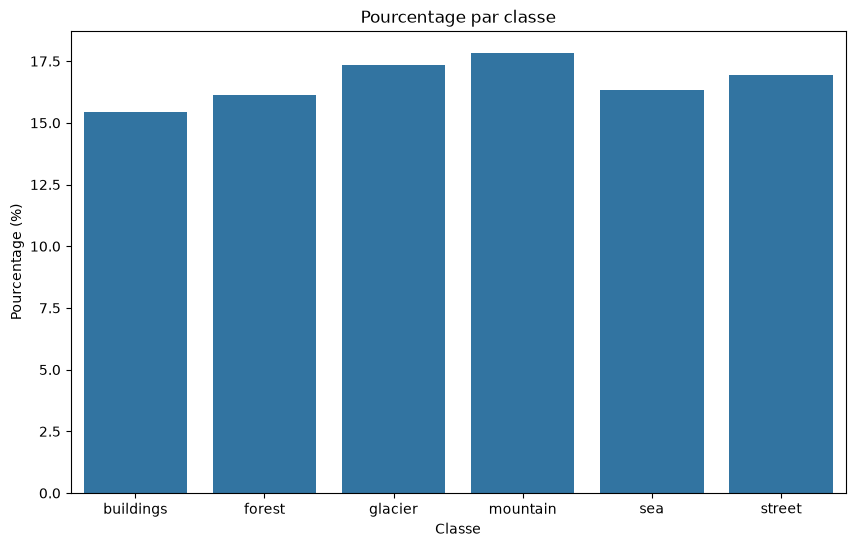

In [102]:
data = explorationPreparation()
df = pd.DataFrame(data)
plt.figure(figsize=(10, 6))

sns.barplot(
        data=df,
        x="classe",
        y="porcentage"
)

plt.title("Pourcentage par classe")
plt.xlabel("Classe")
plt.ylabel("Pourcentage (%)")

plt.show()

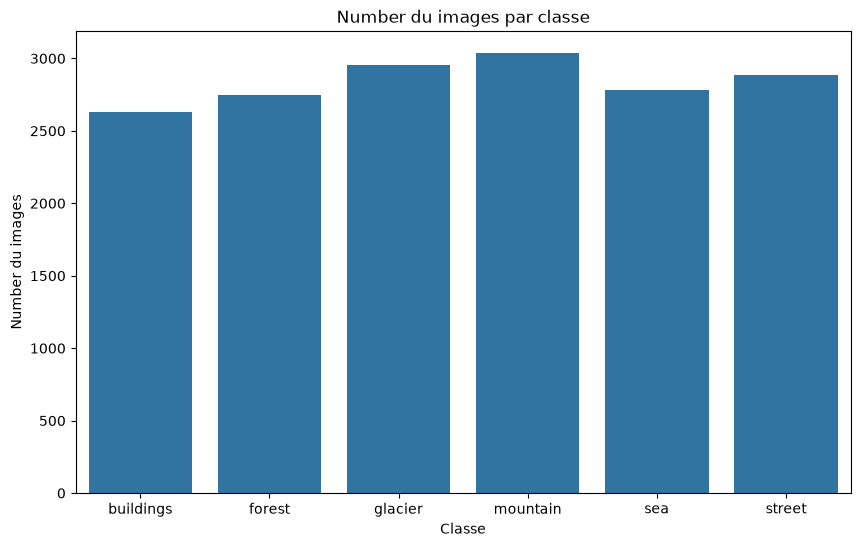

In [103]:
data = explorationPreparation()
df = pd.DataFrame(data)
plt.figure(figsize=(10, 6))

sns.barplot(
        data=df,
        x="classe",
        y="totalImage"
)

plt.title("Number du images par classe")
plt.xlabel("Classe")
plt.ylabel("Number du images")

plt.show()

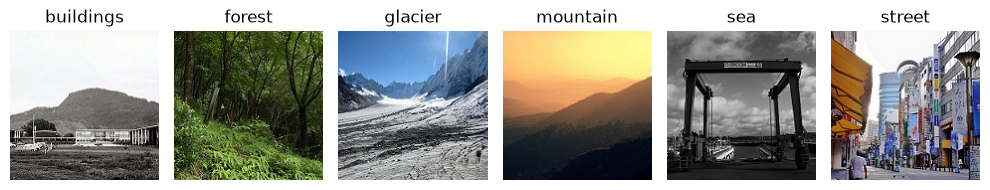

In [104]:
from PIL import Image

imagesData = getImagesClasse()

plt.figure(figsize=(10, 6))
for i, item in enumerate(imagesData):

    image = Image.open(item["images"][0])
    plt.subplot(1, len(data), i+1)
    plt.imshow(image)
    plt.title(item["classe"])
    plt.axis("off")

plt.tight_layout()
plt.show()
        


In [105]:
from collections import Counter

imagesData = getImagesClasse()

for item in imagesData:
    dimensions = Counter()
    formats = Counter()
    modes = Counter()
    erreurs = 0
    for chemin_image in item["images"]:
        try:
            with Image.open(chemin_image) as image:
                dimensions[image.size] += 1
                formats[image.format] += 1
                modes[image.mode] += 1 
        except Exception:
            erreurs += 1
    print(f"\nClasse : {item['classe']}")
    print("Dimensions :", dimensions)
    print("Formats :", formats)
    print("Modes :", modes)
    print("Images illisibles :", erreurs)



Classe : buildings
Dimensions : Counter({(150, 150): 2627, (150, 124): 1})
Formats : Counter({'JPEG': 2628})
Modes : Counter({'RGB': 2628})
Images illisibles : 0

Classe : forest
Dimensions : Counter({(150, 150): 2736, (150, 113): 2, (150, 108): 2, (150, 133): 1, (150, 115): 1, (150, 135): 1, (150, 141): 1, (150, 136): 1})
Formats : Counter({'JPEG': 2745})
Modes : Counter({'RGB': 2745})
Images illisibles : 0

Classe : glacier
Dimensions : Counter({(150, 150): 2936, (150, 111): 3, (150, 110): 2, (150, 149): 2, (150, 76): 2, (150, 105): 1, (150, 120): 1, (150, 143): 1, (150, 146): 1, (150, 134): 1, (150, 142): 1, (150, 123): 1, (150, 119): 1, (150, 102): 1, (150, 72): 1, (150, 97): 1, (150, 135): 1})
Formats : Counter({'JPEG': 2957})
Modes : Counter({'RGB': 2957})
Images illisibles : 0

Classe : mountain
Dimensions : Counter({(150, 150): 3018, (150, 144): 2, (150, 131): 2, (150, 81): 2, (150, 134): 1, (150, 135): 1, (150, 123): 1, (150, 113): 1, (150, 142): 1, (150, 103): 1, (150, 136):

In [106]:
import hashlib
from collections import defaultdict, Counter

imagesData = getImagesClasse()

MIN_WIDTH = 100
MIN_HEIGHT = 100

duplicates = []
too_small = []
same_color = defaultdict(list)
erreurs = 0

hashes = {}

for item in imagesData:
    classe = item["classe"]
    for chemin_image in item["images"]:
        try:
            with Image.open(chemin_image) as image:
                width, height = image.size

                if width < MIN_WIDTH or height < MIN_HEIGHT:
                    too_small.append({
                        "classe": classe,
                        "chemin": chemin_image,
                        "dimensions": image.size
                    })

                with open(chemin_image, "rb") as fichier:
                        contenu = fichier.read()
                        hash_image = hashlib.md5(contenu).hexdigest()

                if hash_image in hashes:
                    duplicates.append({
                        "originale": hashes[hash_image],
                        "doublon": chemin_image
                    })
                else:
                    hashes[hash_image] = chemin_image

                image_rgb = image.convert("RGB")
                image_reduite = image_rgb.resize((50, 50))
                couleur = image_reduite.quantize(
                    colors=1
                ).convert("RGB").getpixel((0, 0))

                same_color[couleur].append({
                    "classe": classe,
                    "chemin": chemin_image
                })

        except Exception:
            erreurs += 1

print("Nombre de doublons :", len(duplicates))
print("Nombre d'images trop petites :", len(too_small))
print("Nombre de groupes de couleurs identiques :",
      sum(1 for images in same_color.values() if len(images) > 1))
print("Nombre d'erreurs :", erreurs)

print("\n--- DOUBLONS ---")
for item in duplicates[:10]:
    print("Originale :", item["originale"])
    print("Doublon   :", item["doublon"])
    print()

Nombre de doublons : 18
Nombre d'images trop petites : 6
Nombre de groupes de couleurs identiques : 970
Nombre d'erreurs : 0

--- DOUBLONS ---
Originale : c:\Users\ycode\Documents\workespace\VisionClassifier\data\Intel_Image_Classification\data_classifier\forest\15657.jpg
Doublon   : c:\Users\ycode\Documents\workespace\VisionClassifier\data\Intel_Image_Classification\data_classifier\forest\18807.jpg

Originale : c:\Users\ycode\Documents\workespace\VisionClassifier\data\Intel_Image_Classification\data_classifier\forest\8688.jpg
Doublon   : c:\Users\ycode\Documents\workespace\VisionClassifier\data\Intel_Image_Classification\data_classifier\forest\8689.jpg

Originale : c:\Users\ycode\Documents\workespace\VisionClassifier\data\Intel_Image_Classification\data_classifier\glacier\21469.jpg
Doublon   : c:\Users\ycode\Documents\workespace\VisionClassifier\data\Intel_Image_Classification\data_classifier\mountain\14341.jpg

Originale : c:\Users\ycode\Documents\workespace\VisionClassifier\data\Int

In [107]:
from sklearn.model_selection import train_test_split
import tensorflow as tf
imagesData = getImagesClasse()
X = []
y = []
for item in imagesData:
    for chemin_image in item["images"]:
        X.append(chemin_image)
        y.append(item["classe"])


# train 
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# validation 
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

# Dataset decoding and batching are configured below.

In [108]:
IMAGE_SIZE = (150, 150)
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE


In [109]:
class_names = sorted(set(y))
class_to_index = {name: index for index, name in enumerate(class_names)}

def make_dataset(paths, labels, training=False):
    encoded_labels = [class_to_index[label] for label in labels]
    dataset = tf.data.Dataset.from_tensor_slices((paths, encoded_labels))
    if training:
        dataset = dataset.shuffle(len(paths), seed=42, reshuffle_each_iteration=True)

    def load_image(path, label):
        image = tf.io.read_file(path)
        image = tf.io.decode_jpeg(image, channels=3)
        image = tf.image.resize(image, IMAGE_SIZE)
        return image, tf.cast(label, tf.int32)

    dataset = dataset.map(load_image, num_parallel_calls=AUTOTUNE)
    return dataset.batch(BATCH_SIZE).prefetch(AUTOTUNE)

train_ds = make_dataset(X_train, y_train, training=True)
val_ds = make_dataset(X_val, y_val)
test_ds = make_dataset(X_test, y_test)

for images, labels in train_ds.take(1):
    print("Image batch:", images.shape, "Label batch:", labels.shape)


Image batch: (32, 150, 150, 3) Label batch: (32,)


In [110]:
from tensorflow.keras import layers, models

data_augmentation = models.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
    layers.RandomTranslation(
        height_factor=0.1,
        width_factor=0.1
    )
], name="data_augmentation")

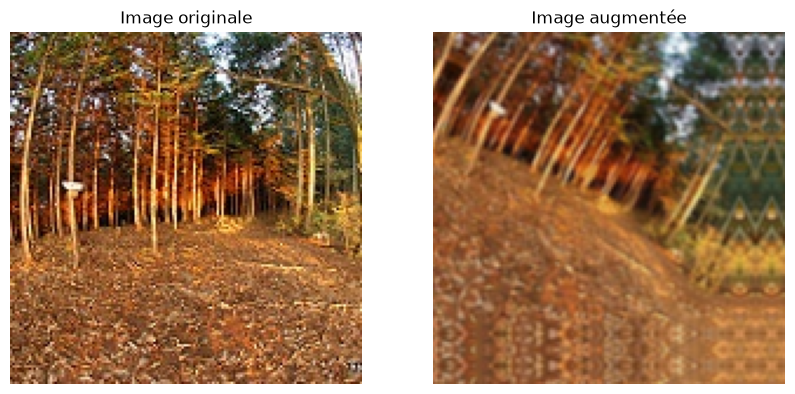

In [111]:
for images, labels in train_ds.take(1):
    image = images[0]

    augmented_image = data_augmentation(
        tf.expand_dims(image, axis=0),
        training=True
    )[0]

    plt.figure(figsize=(10, 5))

    plt.subplot(1, 2, 1)
    plt.imshow(image.numpy().astype("uint8"))
    plt.title("Image originale")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(
        tf.clip_by_value(augmented_image, 0, 255).numpy().astype("uint8")
    )
    plt.title("Image augmentée")
    plt.axis("off")

    plt.show()

In [112]:
num_classes = len(class_names)
image_size = (*IMAGE_SIZE, 3)

model = models.Sequential([

    layers.Input(shape=image_size),
    layers.Rescaling(1./255),
    data_augmentation,
    layers.Conv2D(32, 3, padding="same", use_bias=False),
    layers.BatchNormalization(),
    layers.ReLU(),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, padding="same", use_bias=False),
    layers.BatchNormalization(),
    layers.ReLU(),
    layers.MaxPooling2D(),
    layers.Conv2D(128, 3, padding="same", use_bias=False),
    layers.BatchNormalization(),
    layers.ReLU(),
    layers.MaxPooling2D(),
    layers.Conv2D(256, 3, padding="same", use_bias=False),
    layers.BatchNormalization(),
    layers.ReLU(),
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.35),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.25),
    layers.Dense(num_classes, activation="softmax")
])




model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)



In [113]:
import tensorflow as tf
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau


checkpoint_callback = tf.keras.callbacks.ModelCheckpoint(
    filepath=BEST_MODEL_PATH,
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=6,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=1e-6,
    verbose=1
)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=30,
    shuffle=False,
    callbacks=[early_stopping, reduce_lr, checkpoint_callback],
    verbose=1
)


Epoch 1/30
373/373 ━━━━━━━━━━━━━━━━━━━━ 0s 297ms/step - accuracy: 0.5660 - loss: 1.0908
Epoch 1: val_loss improved from None to 1.12713, saving model to c:\Users\ycode\Documents\workespace\VisionClassifier\models\scene_classifier_best.keras

Epoch 1: finished saving model to c:\Users\ycode\Documents\workespace\VisionClassifier\models\scene_classifier_best.keras
373/373 ━━━━━━━━━━━━━━━━━━━━ 122s 321ms/step - accuracy: 0.5660 - loss: 1.0908 - val_accuracy: 0.5127 - val_loss: 1.1271 - learning_rate: 0.0010
Epoch 2/30
373/373 ━━━━━━━━━━━━━━━━━━━━ 0s 430ms/step - accuracy: 0.6601 - loss: 0.9016
Epoch 2: val_loss did not improve from 1.12713
373/373 ━━━━━━━━━━━━━━━━━━━━ 169s 452ms/step - accuracy: 0.6601 - loss: 0.9016 - val_accuracy: 0.5022 - val_loss: 2.2273 - learning_rate: 0.0010
Epoch 3/30
373/373 ━━━━━━━━━━━━━━━━━━━━ 0s 402ms/step - accuracy: 0.7003 - loss: 0.8023
Epoch 3: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.

Epoch 3: val_loss did not improve from 1.12713

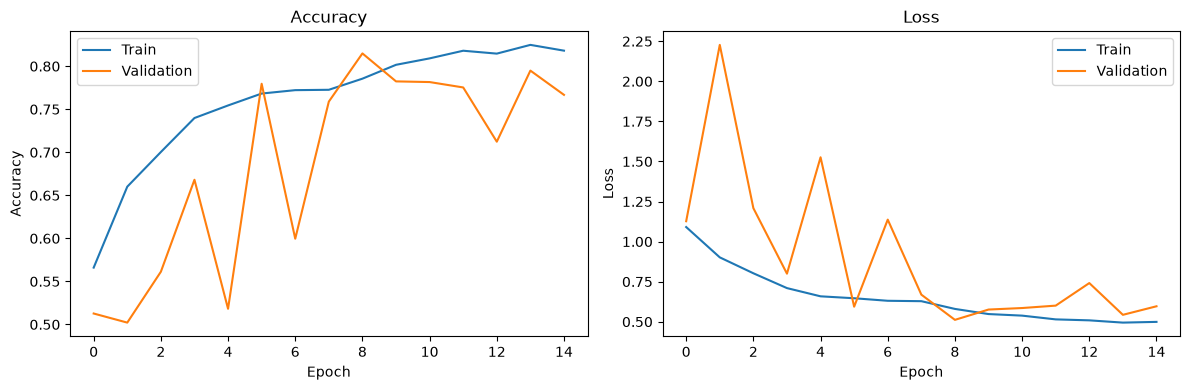

In [114]:

history_dict = history.history

plt.figure(figsize=(12, 4))

# Accuracy
plt.subplot(1, 2, 1)
plt.plot(history_dict["accuracy"], label="Train")
plt.plot(history_dict["val_accuracy"], label="Validation")
plt.title("Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

# Loss
plt.subplot(1, 2, 2)
plt.plot(history_dict["loss"], label="Train")
plt.plot(history_dict["val_loss"], label="Validation")
plt.title("Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [115]:
import json


with open(CLASS_NAMES_PATH, "w", encoding="utf-8") as f:
    json.dump(class_names, f, ensure_ascii=False)

print("Classes sauvegardées :", class_names)

Classes sauvegardées : ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']


In [116]:
import numpy as np
import tensorflow as tf

def predict_image(image_path, model, class_names):
    image = tf.keras.utils.load_img(
        image_path,
        target_size=(150, 150),
        color_mode="rgb"
    )
    image_array = tf.keras.utils.img_to_array(image)
    image_array = tf.expand_dims(image_array, axis=0)

    probabilities = model.predict(image_array, verbose=0)[0]
    predicted_index = int(np.argmax(probabilities))

    ranking = sorted(
        zip(class_names, probabilities.tolist()),
        key=lambda item: item[1],
        reverse=True
    )

    return class_names[predicted_index], float(probabilities[predicted_index]), ranking


image_path = str(PROJECT_ROOT / "data" / "Intel_Image_Classification" / "seg_pred" / "22.jpg")

label, confidence, ranking = predict_image(image_path, model, class_names)

print(f"Classe prédite : {label}")
print(f"Confiance : {confidence:.2%}")
print("Autres probabilités :", ranking)

Classe prédite : forest
Confiance : 98.94%
Autres probabilités : [('forest', 0.9894090890884399), ('buildings', 0.004983343183994293), ('street', 0.0035078295040875673), ('glacier', 0.0009657260379754007), ('sea', 0.0009341450640931726), ('mountain', 0.00019979405624326319)]


In [117]:
model = tf.keras.models.load_model(BEST_MODEL_PATH)

with open(CLASS_NAMES_PATH, "r", encoding="utf-8") as f:
    class_names = json.load(f)

model.evaluate(test_ds, verbose=1)

80/80 ━━━━━━━━━━━━━━━━━━━━ 9s 101ms/step - accuracy: 0.8177 - loss: 0.5346


[0.5346291661262512, 0.8176838755607605]